In [2]:
# PyTorch and deep learning
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import (
    Dataset, DataLoader, Subset
)

# Image processing
from PIL import Image
from torchvision import transforms

# Data handling
import os
import random
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset splitting and evaluation
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):

    for file in files:

        if 'FoodClass' in file:

            print(os.path.join(root, file))

/content/drive/MyDrive/FoodClass Fruit, Vegetable, Meat, Fish dataset.zip


In [5]:
zip_path = "/content/drive/MyDrive/FoodClass Fruit, Vegetable, Meat, Fish dataset.zip"

extract_path = "/content/FoodClass"

In [6]:
import zipfile
import os

with zipfile.ZipFile(zip_path, 'r') as zip_ref:

    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

print(os.listdir(extract_path))

Dataset extracted successfully!
['FoodClass Fruit, Vegetable, Meat, Fish dataset']


In [7]:
for root, dirs, files in os.walk(extract_path):

    level = root.replace(
        extract_path, ''
    ).count(os.sep)

    if level <= 3:

        print("  " * level + os.path.basename(root) + "/")

        image_count = sum(
            1 for f in files
            if f.lower().endswith(
                ('.jpg', '.jpeg', '.png', '.webp')
            )
        )

        if image_count > 0:

            print(
                "  " * (level + 1),
                "Images:", image_count
            )

FoodClass/
  FoodClass Fruit, Vegetable, Meat, Fish dataset/


In [8]:
import os

inner_path = os.path.join(
    extract_path,
    "FoodClass Fruit, Vegetable, Meat, Fish dataset"
)

print("Inside folder:")
print(os.listdir(inner_path))

Inside folder:
['FoodClass2.zip']


In [9]:
for root, dirs, files in os.walk(inner_path):

    print("\nFolder:", root)

    print("Subfolders:", dirs)

    print("Files:", files[:10])


Folder: /content/FoodClass/FoodClass Fruit, Vegetable, Meat, Fish dataset
Subfolders: []
Files: ['FoodClass2.zip']


In [10]:
import zipfile
import os

inner_zip_path = os.path.join(
    inner_path,
    "FoodClass2.zip"
)

final_extract_path = "/content/FoodDataset"

with zipfile.ZipFile(inner_zip_path, 'r') as zip_ref:

    zip_ref.extractall(final_extract_path)

print("Food dataset extracted successfully!")

print(os.listdir(final_extract_path))

Food dataset extracted successfully!
['FoodClass2']


In [11]:
for root, dirs, files in os.walk(final_extract_path):

    level = root.replace(
        final_extract_path, ''
    ).count(os.sep)

    if level <= 3:

        print("  " * level + os.path.basename(root) + "/")

        image_count = sum(
            1 for f in files
            if f.lower().endswith(
                ('.jpg', '.jpeg', '.png', '.webp')
            )
        )

        if image_count > 0:

            print(
                "  " * (level + 1),
                "Images:", image_count
            )

FoodDataset/
  FoodClass2/
    Fish/
      Mackerel/
      Tilapia/
      Silver_Barb/
      Tuna/
      Fish_Eye/
    Meat/
      Beef/
      Chicken/
      Mutton/
    Vegetables/
      Bittergourd/
      Carrot/
      Cucumber/
      Okra/
      Capsicum/
      Bellpepper/
      Potato/
      Tomato/
    Fruits/
      Orange/
      Banana/
      Mango/
      Apple/
      Strawberry/


In [12]:
import os

data_dir = "/content/FoodDataset/FoodClass2"

categories = [
    "Fruits",
    "Meat",
    "Fish",
    "Vegetables"
]

image_extensions = (
    '.jpg', '.jpeg', '.png', '.webp', '.bmp'
)

total_images = 0

for category in categories:

    category_path = os.path.join(
        data_dir, category
    )

    print("\n", category.upper())

    for food_class in os.listdir(category_path):

        class_path = os.path.join(
            category_path, food_class
        )

        if os.path.isdir(class_path):

            count = 0

            for root, dirs, files in os.walk(class_path):

                count += sum(
                    1 for file in files
                    if file.lower().endswith(image_extensions)
                )

            print(food_class, ":", count, "images")

            total_images += count

print("\nTotal Images:", total_images)


 FRUITS
Orange : 14123 images
Banana : 7511 images
Mango : 1198 images
Apple : 7868 images
Strawberry : 1199 images

 MEAT
Beef : 3268 images
Chicken : 1300 images
Mutton : 1000 images

 FISH
Mackerel : 859 images
Tilapia : 840 images
Silver_Barb : 1200 images
Tuna : 837 images
Fish_Eye : 4390 images

 VEGETABLES
Bittergourd : 684 images
Carrot : 12318 images
Cucumber : 2118 images
Okra : 973 images
Capsicum : 1891 images
Bellpepper : 1202 images
Potato : 2538 images
Tomato : 17695 images

Total Images: 85012


In [13]:
data_dir = "/content/FoodDataset/FoodClass2"

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision
from torchvision import transforms

from torch.utils.data import Dataset, DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from PIL import Image

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

torch.manual_seed(42)
np.random.seed(42)

Using device: cuda


In [15]:
data_dir = "/content/FoodDataset/FoodClass2"

categories = [
    "Fruits",
    "Meat",
    "Fish",
    "Vegetables"
]

print("Dataset Categories:")

for category in categories:

    print(category)

Dataset Categories:
Fruits
Meat
Fish
Vegetables


In [16]:
image_paths = []
labels = []

image_extensions = (
    ".jpg", ".jpeg", ".png", ".webp", ".bmp"
)

for category in categories:

    category_path = os.path.join(
        data_dir, category
    )

    for food_class in os.listdir(category_path):

        class_path = os.path.join(
            category_path, food_class
        )

        if os.path.isdir(class_path):

            for root, dirs, files in os.walk(class_path):

                for file in files:

                    if file.lower().endswith(image_extensions):

                        image_path = os.path.join(
                            root, file
                        )

                        image_paths.append(image_path)

                        labels.append(food_class)

# Create DataFrame
df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

print("Dataset loaded successfully!")

print("Total Images:", len(df))

print("Total Classes:", df["label"].nunique())

Dataset loaded successfully!
Total Images: 85012
Total Classes: 21


In [17]:
class_counts = df["label"].value_counts().sort_index()

print("Images per class:\n")

print(class_counts)

print("\nTotal Images:", class_counts.sum())

Images per class:

label
Apple           7868
Banana          7511
Beef            3268
Bellpepper      1202
Bittergourd      684
Capsicum        1891
Carrot         12318
Chicken         1300
Cucumber        2118
Fish_Eye        4390
Mackerel         859
Mango           1198
Mutton          1000
Okra             973
Orange         14123
Potato          2538
Silver_Barb     1200
Strawberry      1199
Tilapia          840
Tomato         17695
Tuna             837
Name: count, dtype: int64

Total Images: 85012


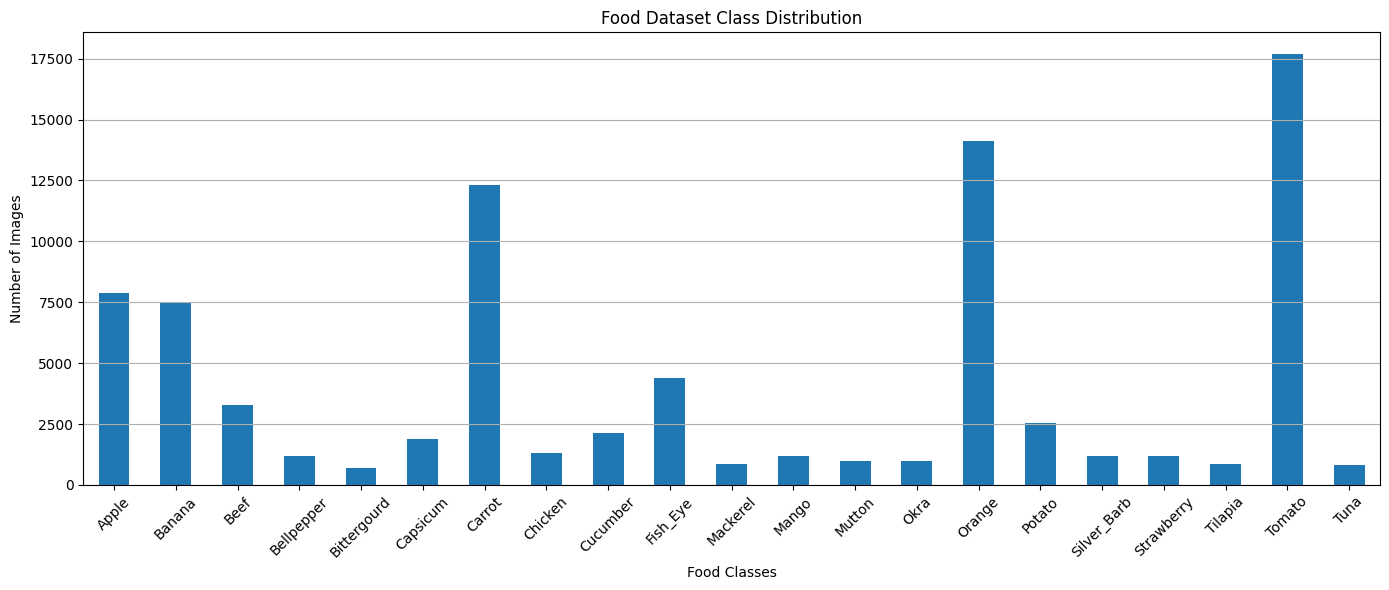

In [18]:
plt.figure(figsize=(14, 6))

class_counts.plot(kind="bar")

plt.title("Food Dataset Class Distribution")

plt.xlabel("Food Classes")

plt.ylabel("Number of Images")

plt.xticks(rotation=45)

plt.grid(axis="y")

plt.tight_layout()

plt.show()

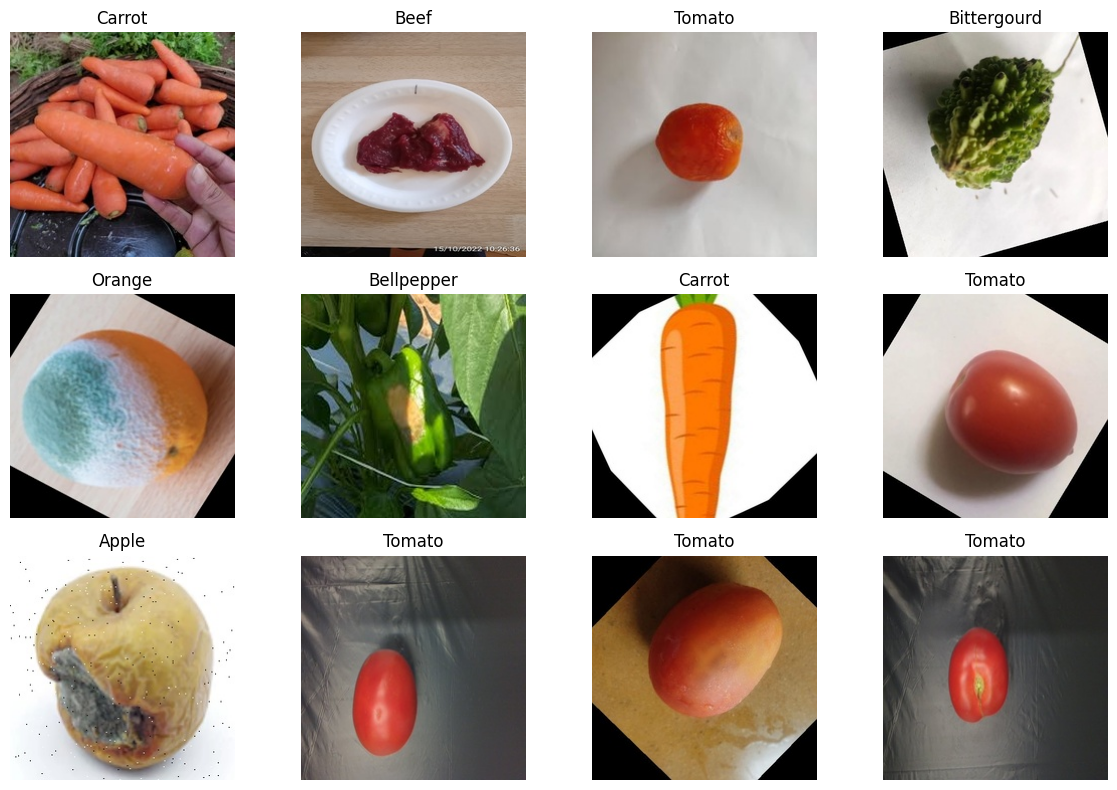

In [19]:
plt.figure(figsize=(12, 8))

sample_df = df.sample(
    n=min(12, len(df)),
    random_state=42
).reset_index(drop=True)

for i in range(len(sample_df)):

    image = Image.open(
        sample_df.loc[i, "image_path"]
    ).convert("RGB")

    plt.subplot(3, 4, i + 1)

    plt.imshow(image)

    plt.title(sample_df.loc[i, "label"])

    plt.axis("off")

plt.tight_layout()

plt.show()

In [20]:
class_names = sorted(df["label"].unique())

class_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

df["label_id"] = df["label"].map(class_to_idx)

print("Class Mapping:\n")

for name, idx in class_to_idx.items():

    print(name, ":", idx)

print("\nTotal Classes:", len(class_names))

Class Mapping:

Apple : 0
Banana : 1
Beef : 2
Bellpepper : 3
Bittergourd : 4
Capsicum : 5
Carrot : 6
Chicken : 7
Cucumber : 8
Fish_Eye : 9
Mackerel : 10
Mango : 11
Mutton : 12
Okra : 13
Orange : 14
Potato : 15
Silver_Barb : 16
Strawberry : 17
Tilapia : 18
Tomato : 19
Tuna : 20

Total Classes: 21


In [21]:
IMG_SIZE = 128

BATCH_SIZE = 32

# Training transformation with data augmentation
train_transform = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# Validation and testing transformation
val_transform = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

print("Image preprocessing completed!")

print("Data augmentation applied to training images.")

Image preprocessing completed!
Data augmentation applied to training images.


In [22]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label_id"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_id"],
    random_state=42
)

print("Training Images:", len(train_df))

print("Validation Images:", len(val_df))

print("Testing Images:", len(test_df))

print("\nTraining Percentage:",
      len(train_df) / len(df) * 100)

print("Validation Percentage:",
      len(val_df) / len(df) * 100)

print("Testing Percentage:",
      len(test_df) / len(df) * 100)

Training Images: 59508
Validation Images: 12752
Testing Images: 12752

Training Percentage: 69.99952947819132
Validation Percentage: 15.000235260904343
Testing Percentage: 15.000235260904343


In [23]:
class FoodDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.dataframe = dataframe.reset_index(drop=True)

        self.transform = transform

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        image_path = self.dataframe.loc[
            index, "image_path"
        ]

        label = self.dataframe.loc[
            index, "label_id"
        ]

        image = Image.open(image_path).convert("RGB")

        if self.transform:

            image = self.transform(image)

        return image, int(label)


# Apply augmentation only to training images
train_dataset = FoodDataset(
    train_df, train_transform
)

val_dataset = FoodDataset(
    val_df, val_transform
)

test_dataset = FoodDataset(
    test_df, val_transform
)

print("Dataset objects created successfully!")

print("Training Images:", len(train_dataset))

print("Validation Images:", len(val_dataset))

print("Testing Images:", len(test_dataset))

Dataset objects created successfully!
Training Images: 59508
Validation Images: 12752
Testing Images: 12752


In [24]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Training Batches:", len(train_loader))

print("Validation Batches:", len(val_loader))

print("Testing Batches:", len(test_loader))

Training Batches: 1860
Validation Batches: 399
Testing Batches: 399


In [25]:
images, labels = next(iter(train_loader))

print("Image Batch Shape:", images.shape)

print("Label Batch Shape:", labels.shape)

print(
    "First Image Label:",
    class_names[labels[0].item()]
)

Image Batch Shape: torch.Size([32, 3, 128, 128])
Label Batch Shape: torch.Size([32])
First Image Label: Orange


In [26]:
class SimpleCNN(nn.Module):

    def __init__(self):

        super(SimpleCNN, self).__init__()

        # First convolution layer
        self.conv1 = nn.Conv2d(
            3, 16, kernel_size=3, padding=1
        )

        # Second convolution layer
        self.conv2 = nn.Conv2d(
            16, 32, kernel_size=3, padding=1
        )

        # Third convolution layer
        self.conv3 = nn.Conv2d(
            32, 64, kernel_size=3, padding=1
        )

        # Max pooling
        self.pool = nn.MaxPool2d(2, 2)

        # Dropout for overfitting prevention
        self.dropout = nn.Dropout(0.5)

        # Fully connected layers
        self.fc1 = nn.Linear(64 * 16 * 16, 128)

        self.fc2 = nn.Linear(128, len(class_names))

    def forward(self, x):

        # Convolution + ReLU + Pooling
        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = self.pool(F.relu(self.conv3(x)))

        # Flatten
        x = torch.flatten(x, 1)

        # Dropout
        x = self.dropout(x)

        # Fully connected layers
        x = F.relu(self.fc1(x))

        x = self.dropout(x)

        x = self.fc2(x)

        return x


# Create model
model = SimpleCNN().to(device)

print(model)

SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=21, bias=True)
)


In [27]:
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total Trainable Parameters:", total_params)

print("Number of Output Classes:", len(class_names))

Total Trainable Parameters: 2123573
Number of Output Classes: 21


In [28]:
learning_rate = 0.001

epochs = 20

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer with L2 regularization (weight decay)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate,
    weight_decay=0.0001
)

print("Learning Rate:", learning_rate)

print("Epochs:", epochs)

print("Optimizer: Adam")

print("Weight Decay:", 0.0001)

print("Loss Function: CrossEntropyLoss")

Learning Rate: 0.001
Epochs: 20
Optimizer: Adam
Weight Decay: 0.0001
Loss Function: CrossEntropyLoss


In [29]:
def train_model(model, train_loader, criterion, optimizer):

    model.train()

    running_loss = 0.0

    correct = 0

    total = 0

    for images, labels in train_loader:

        images = images.to(device)

        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        loss = criterion(outputs, labels)

        # Backward pass
        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        # Calculate accuracy
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total

    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [30]:
def validate_model(model, val_loader, criterion):

    model.eval()

    running_loss = 0.0

    correct = 0

    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)

            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total

    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [31]:
train_losses = []

val_losses = []

train_accuracies = []

val_accuracies = []

best_val_loss = float('inf')

# Early stopping settings
patience = 5

counter = 0

for epoch in range(epochs):

    # Training
    train_loss, train_acc = train_model(
        model,
        train_loader,
        criterion,
        optimizer
    )

    # Validation
    val_loss, val_acc = validate_model(
        model,
        val_loader,
        criterion
    )

    # Store results
    train_losses.append(train_loss)

    val_losses.append(val_loss)

    train_accuracies.append(train_acc)

    val_accuracies.append(val_acc)

    print(f"\nEpoch [{epoch+1}/{epochs}]")

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc*100:.2f}%"
    )

    print(
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_acc*100:.2f}%"
    )

    # Save model when validation loss improves
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        counter = 0

        torch.save(
            model.state_dict(),
            "/content/best_food_cnn.pth"
        )

        print("Best model saved!")

    else:

        counter += 1

        print("Early Stopping Counter:", counter)

    # Stop if validation loss does not improve
    if counter >= patience:

        print("\nEarly Stopping Activated!")

        break

print("\nTraining Completed!")

print("Best Validation Loss:", best_val_loss)

print("Epochs Completed:", len(train_losses))


Epoch [1/20]
Train Loss: 1.0561 | Train Accuracy: 65.73%
Validation Loss: 0.5255 | Validation Accuracy: 81.63%
Best model saved!

Epoch [2/20]
Train Loss: 0.6894 | Train Accuracy: 76.84%
Validation Loss: 0.3835 | Validation Accuracy: 87.51%
Best model saved!

Epoch [3/20]
Train Loss: 0.5893 | Train Accuracy: 80.35%
Validation Loss: 0.3524 | Validation Accuracy: 88.06%
Best model saved!

Epoch [4/20]
Train Loss: 0.5247 | Train Accuracy: 82.55%
Validation Loss: 0.2892 | Validation Accuracy: 90.46%
Best model saved!

Epoch [5/20]
Train Loss: 0.4823 | Train Accuracy: 83.72%
Validation Loss: 0.2764 | Validation Accuracy: 90.52%
Best model saved!

Epoch [6/20]
Train Loss: 0.4511 | Train Accuracy: 84.90%
Validation Loss: 0.2483 | Validation Accuracy: 91.22%
Best model saved!

Epoch [7/20]
Train Loss: 0.4211 | Train Accuracy: 85.91%
Validation Loss: 0.2356 | Validation Accuracy: 92.12%
Best model saved!

Epoch [8/20]
Train Loss: 0.3992 | Train Accuracy: 86.76%
Validation Loss: 0.2138 | Valida

In [32]:
model.load_state_dict(
    torch.load(
        "/content/best_food_cnn.pth",
        map_location=device
    )
)

model.eval()

print("Best model loaded successfully!")

Best model loaded successfully!


In [33]:
y_true = []

y_pred = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        y_true.extend(labels.numpy())

        y_pred.extend(predicted.cpu().numpy())

print("Testing completed!")

print("Total Test Images:", len(y_true))

Testing completed!
Total Test Images: 12752


In [34]:
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print("CNN MODEL EVALUATION")

print(" ")

print(f"Test Accuracy  : {accuracy*100:.2f}%")

print(f"Test Precision : {precision*100:.2f}%")

print(f"Test Recall    : {recall*100:.2f}%")

print(f"Test F1-Score  : {f1*100:.2f}%")

CNN MODEL EVALUATION
 
Test Accuracy  : 94.26%
Test Precision : 94.17%
Test Recall    : 94.26%
Test F1-Score  : 94.13%


In [35]:
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       Apple       0.93      0.96      0.95      1180
      Banana       0.97      0.98      0.97      1126
        Beef       1.00      1.00      1.00       490
  Bellpepper       0.73      0.49      0.59       180
 Bittergourd       1.00      0.95      0.98       103
    Capsicum       0.95      1.00      0.97       284
      Carrot       0.93      0.97      0.95      1848
     Chicken       0.99      0.98      0.99       195
    Cucumber       0.76      0.82      0.79       317
    Fish_Eye       0.99      1.00      0.99       659
    Mackerel       0.83      0.95      0.88       129
       Mango       0.84      0.75      0.79       180
      Mutton       0.99      1.00      0.99       150
        Okra       0.79      0.62      0.69       146
      Orange       0.96      0.93      0.94      2119
      Potato       0.93      0.87      0.90       380
 Silver_Barb       1.00      1.00      1.00       180
  Strawberry       0.95    

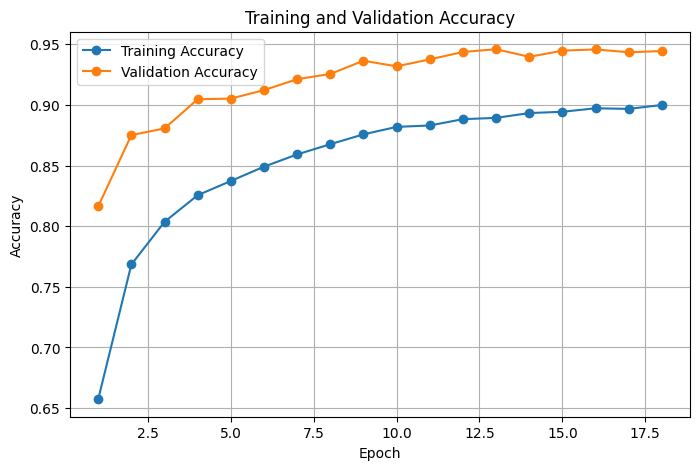

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(train_accuracies) + 1),
    train_accuracies,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    range(1, len(val_accuracies) + 1),
    val_accuracies,
    marker='o',
    label='Validation Accuracy'
)

plt.title("Training and Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

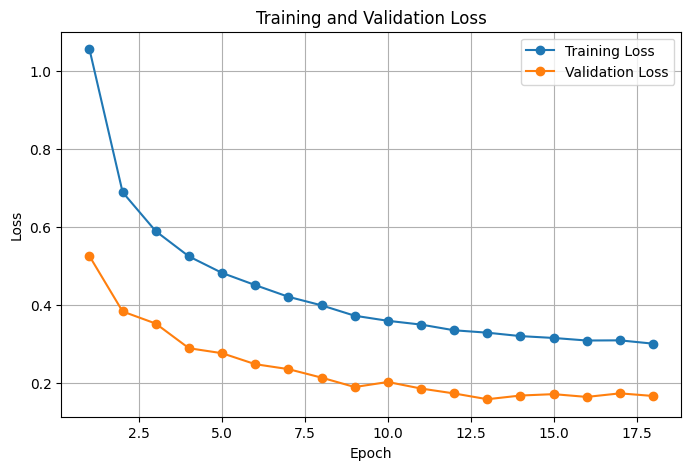

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker='o',
    label='Training Loss'
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    marker='o',
    label='Validation Loss'
)

plt.title("Training and Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

<Figure size 1400x1200 with 0 Axes>

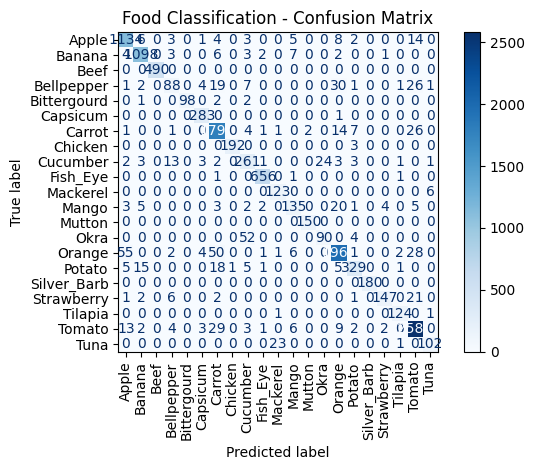

In [38]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    xticks_rotation=90,
    values_format="d"
)

plt.title("Food Classification - Confusion Matrix")

plt.tight_layout()

plt.show()

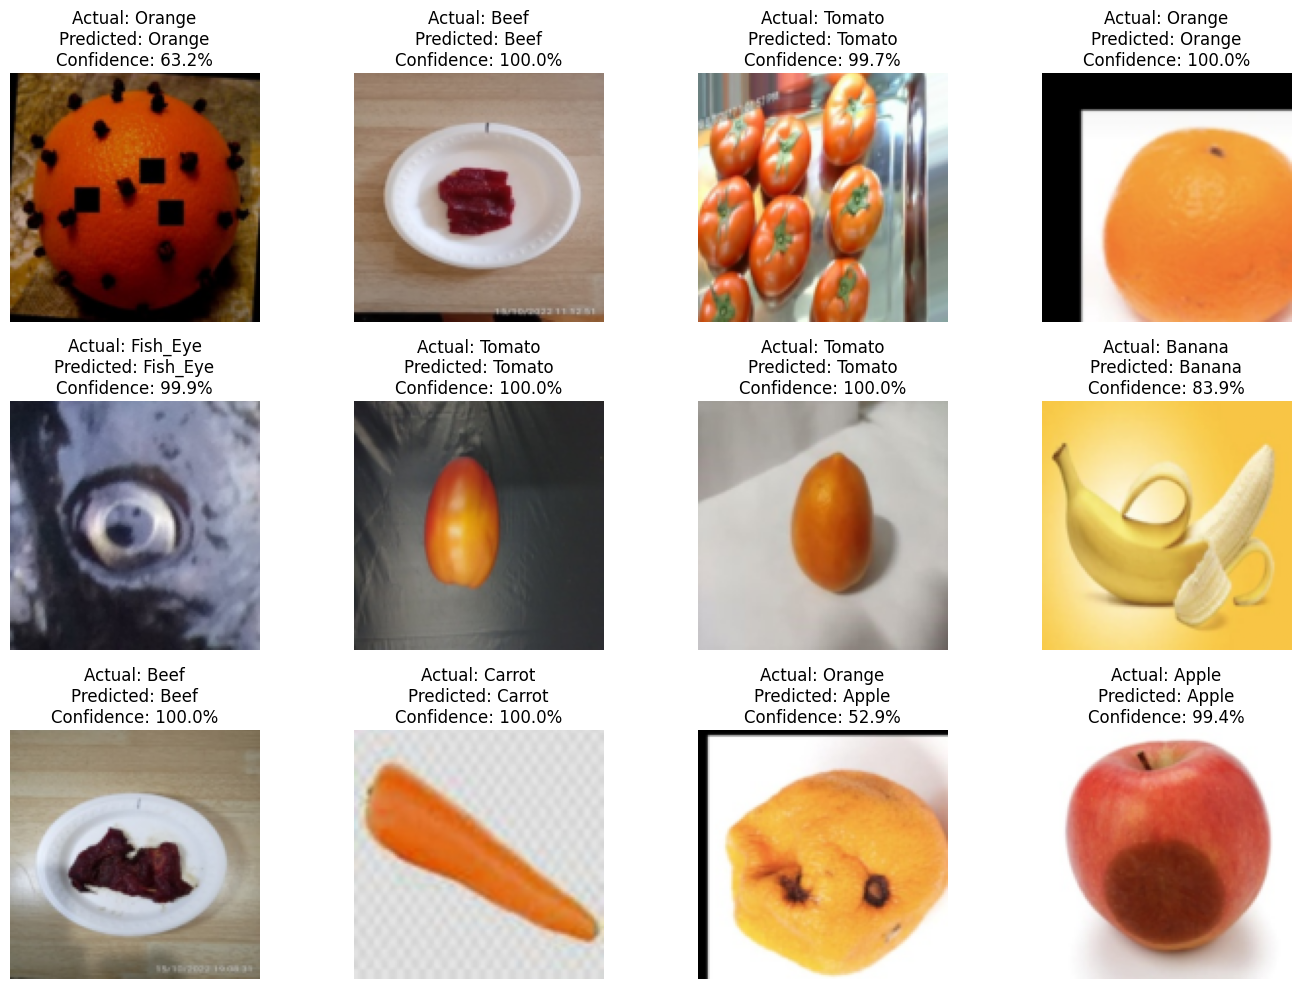

In [39]:
plt.figure(figsize=(14, 10))

model.eval()

for i in range(min(12, len(test_dataset))):

    image, actual_label = test_dataset[i]

    image_input = image.unsqueeze(0).to(device)

    with torch.no_grad():

        output = model(image_input)

        probabilities = torch.softmax(output, dim=1)

        confidence, predicted = torch.max(
            probabilities, 1
        )

    predicted_label = class_names[predicted.item()]

    actual_name = class_names[actual_label]

    # Denormalize image for visualization
    display_image = image.permute(1, 2, 0) * 0.5 + 0.5

    plt.subplot(3, 4, i + 1)

    plt.imshow(display_image.clamp(0, 1))

    plt.title(
        f"Actual: {actual_name}\n"
        f"Predicted: {predicted_label}\n"
        f"Confidence: {confidence.item()*100:.1f}%"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

In [40]:
results = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],

    "Score (%)": [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ]
})

print("FINAL CNN PERFORMANCE SUMMARY")

display(results)

FINAL CNN PERFORMANCE SUMMARY


,Metric,Score (%)
0,Accuracy,94.259724
1,Precision,94.168666
2,Recall,94.259724
3,F1-Score,94.126520


In [41]:
torch.save(
    model.state_dict(),
    "/content/FoodClass_CNN_Final.pth"
)

print("Final CNN model saved successfully!")

Final CNN model saved successfully!
